<a href="https://colab.research.google.com/github/Bismalaljan/myfirstproject/blob/main/Copy_of_CNN_Architectures_Complete_Explained.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CNN Architectures
## AlexNet • VGG • GoogLeNet/Inception • ResNet • DenseNet





In [ ]:
# 1. Import libraries
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(42)
print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

## 2. Load and prepare CIFAR-10
CIFAR-10 contains 32×32 colour images from 10 classes. We scale pixel values from 0–255 to 0–1.

In [ ]:
(x_train_all, y_train_all), (x_test, y_test) = keras.datasets.cifar10.load_data()
class_names = ["airplane", "automobile", "bird", "cat", "deer",




               "dog", "frog", "horse", "ship", "truck"]

TRAIN_LIMIT = 12000  # Change to 50000 to use the full training set
EPOCHS = 3           # Try 5–10 for a stronger comparison
BATCH_SIZE = 128

x_train = x_train_all[:TRAIN_LIMIT].astype("float32") / 255.0
y_train = y_train_all[:TRAIN_LIMIT].flatten()
x_test = x_test.astype("float32") / 255.0






y_test = y_test.flatten()

print("Train:", x_train.shape, "Test:", x_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1527s 9us/step
Train: (12000, 32, 32, 3) Test: (10000, 32, 32, 3)


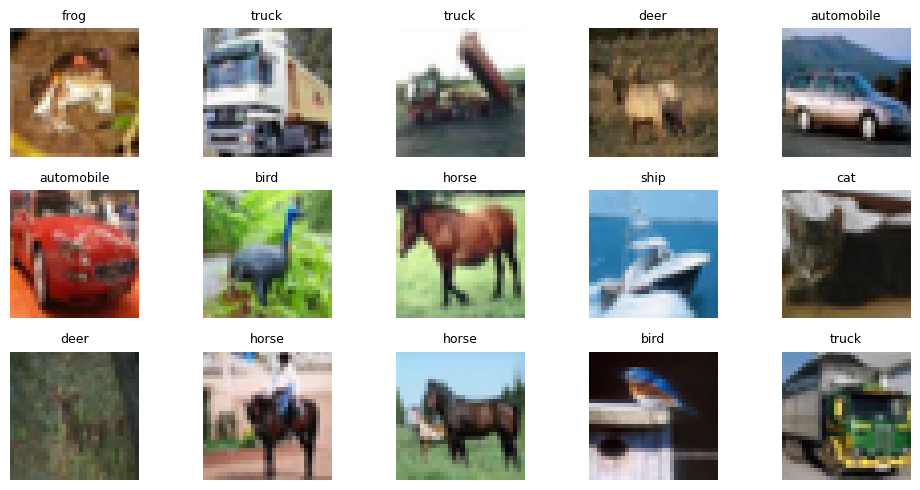

In [ ]:
# View sample images


plt.figure(figsize=(10, 5))
for i in range(15):
    plt.subplot(3, 5, i+1)
    plt.imshow(x_train[i])
    plt.title(class_names[y_train[i]], fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()

## 3. AlexNet — compact educational version

**Main idea:** convolution layers learn features; ReLU adds non-linearity; pooling reduces image dimensions; dropout helps reduce overfitting in the classifier. The original AlexNet was designed for larger images, so this version is adapted to 32×32 CIFAR-10 images.

In [ ]:
def build_alexnet():
    return keras.Sequential([
        layers.Input((32, 32, 3)),
        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(2),
        layers.Conv2D(192, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(2),
        layers.Conv2D(256, 3, padding="same", activation="relu"),
        layers.Conv2D(256, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(2),
        layers.Flatten(),
        layers.Dense(512, activation="relu"),
        layers.Dropout(0.5),
        layers.Dense(256, activation="relu"),
        layers.Dropout(0.5),
        layers.Dense(10, activation="softmax")
    ], name="AlexNet_small")

alexnet = build_alexnet()
alexnet.summary()

Model: "AlexNet_small"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 192)    │       110,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 192)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 256)      │       442,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 8, 8, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     2,097,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,376,842 (12.88 MB)

 Trainable params: 3,376,842 (12.88 MB)

 Non-trainable params: 0 (0.00 B)

## 4. VGG-style CNN

**Main idea:** repeat small 3×3 convolution layers in blocks, with max-pooling between blocks. VGG-16 and VGG-19 refer to versions with 16 and 19 weight layers. This smaller model follows the VGG design idea without reproducing the full original VGG-16.

In [ ]:
def build_vgg_style():
    inputs = keras.Input((32, 32, 3))
    x = inputs
    for filters, count in [(32, 2), (64, 2), (128, 3)]:
        for _ in range(count):
            x = layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
        x = layers.MaxPooling2D()(x)
    x = layers.Flatten()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(10, activation="softmax")(x)
    return keras.Model(inputs, outputs, name="VGG_style")

vgg_model = build_vgg_style()
vgg_model.summary()

Model: "VGG_style"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 961,706 (3.67 MB)

 Trainable params: 961,706 (3.67 MB)

 Non-trainable params: 0 (0.00 B)

## 5. GoogLeNet / Inception-style CNN

**Main idea:** different paths process the same input using 1×1, 3×3, 5×5 convolutions and pooling. Their feature maps are **concatenated**. This captures patterns at multiple spatial scales. This is a simplified Inception design for teaching.

In [ ]:
def inception_block(x, filters):
    f1, f3, f5, fp = filters
    p1 = layers.Conv2D(f1, 1, padding="same", activation="relu")(x)

    p3 = layers.Conv2D(f3, 1, padding="same", activation="relu")(x)
    p3 = layers.Conv2D(f3, 3, padding="same", activation="relu")(p3)

    p5 = layers.Conv2D(f5, 1, padding="same", activation="relu")(x)
    p5 = layers.Conv2D(f5, 5, padding="same", activation="relu")(p5)

    pp = layers.MaxPooling2D(3, strides=1, padding="same")(x)
    pp = layers.Conv2D(fp, 1, padding="same", activation="relu")(pp)
    return layers.Concatenate()([p1, p3, p5, pp])

def build_googlenet_style():
    inputs = keras.Input((32, 32, 3))
    x = layers.Conv2D(32, 3, padding="same", activation="relu")(inputs)
    x = layers.MaxPooling2D()(x)
    x = inception_block(x, (16, 16, 8, 8))
    x = layers.MaxPooling2D()(x)
    x = inception_block(x, (24, 24, 12, 12))
    x = layers.GlobalAveragePooling2D()(x)
    outputs = layers.Dense(10, activation="softmax")(x)
    return keras.Model(inputs, outputs, name="GoogLeNet_Inception_style")

googlenet_model = build_googlenet_style()
googlenet_model.summary()

Model: "GoogLeNet_Inception_style"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_11 (Conv2D)  │ (None, 32, 32,    │        896 │ input_layer_2[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_6     │ (None, 16, 16,    │          0 │ conv2d_11[0][0]   │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_13 (Conv2D)  │ (None, 16, 16,    │        528 │ max_pooling2d_6[… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_15 (Conv2D)  │ (None, 16, 16, 8) │        264 │ max_pooling2d_6[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_7     │ (None, 16, 16,    │          0 │ max_pooling2d_6[… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_12 (Conv2D)  │ (None, 16, 16,    │        528 │ max_pooling2d_6[… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_14 (Conv2D)  │ (None, 16, 16,    │      2,320 │ conv2d_13[0][0]   │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_16 (Conv2D)  │ (None, 16, 16, 8) │      1,608 │ conv2d_15[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_17 (Conv2D)  │ (None, 16, 16, 8) │        264 │ max_pooling2d_7[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 16, 16,    │          0 │ conv2d_12[0][0],  │
│ (Concatenate)       │ 48)               │            │ conv2d_14[0][0],  │
│                     │                   │            │ conv2d_16[0][0],  │
│                     │                   │            │ conv2d_17[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_8     │ (None, 8, 8, 48)  │          0 │ concatenate[0][0] │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_19 (Conv2D)  │ (None, 8, 8, 24)  │      1,176 │ max_pooling2d_8[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_21 (Conv2D)  │ (None, 8, 8, 12)  │        588 │ max_pooling2d_8[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_9     │ (None, 8, 8, 48)  │          0 │ max_pooling2d_8[… │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_18 (Conv2D)  │ (None, 8, 8, 24)  │      1,176 │ max_pooling2d_8[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_20 (Conv2D)  │ (None, 8, 8, 24)  │      5,208 │ conv2d_19[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_22 (Conv2D)  │ (None, 8, 8, 12)  │      3,612 │ conv2d_21[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_23 (Conv2D)  │ (None, 8, 8, 12)  │        588 │ max_pooling2d_9[

 Total params: 19,486 (76.12 KB)

 Trainable params: 19,486 (76.12 KB)

 Non-trainable params: 0 (0.00 B)

## 6. ResNet-style CNN

**Main idea:** a residual block adds the input shortcut to the learned transformation: **output = F(x) + x**. This helps information and gradients flow through deeper networks. If the tensor shape changes, a 1×1 convolution matches the shortcut shape before addition.

In [ ]:
def residual_block(x, filters, stride=1):
    shortcut = x
    y = layers.Conv2D(filters, 3, strides=stride, padding="same",
                      use_bias=False)(x)
    y = layers.BatchNormalization()(y)
    y = layers.Activation("relu")(y)
    y = layers.Conv2D(filters, 3, padding="same", use_bias=False)(y)
    y = layers.BatchNormalization()(y)

    if stride != 1 or int(shortcut.shape[-1]) != filters:
        shortcut = layers.Conv2D(filters, 1, strides=stride,
                                 padding="same", use_bias=False)(shortcut)
        shortcut = layers.BatchNormalization()(shortcut)

    y = layers.Add()([y, shortcut])  # residual addition
    return layers.Activation("relu")(y)

def build_resnet_style():
    inputs = keras.Input((32, 32, 3))
    x = layers.Conv2D(32, 3, padding="same", use_bias=False)(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = residual_block(x, 32)
    x = residual_block(x, 64, stride=2)
    x = residual_block(x, 64)
    x = residual_block(x, 128, stride=2)
    x = layers.GlobalAveragePooling2D()(x)
    outputs = layers.Dense(10, activation="softmax")(x)
    return keras.Model(inputs, outputs, name="ResNet_style")

resnet_model = build_resnet_style()
resnet_model.summary()

Model: "ResNet_style"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_24 (Conv2D)  │ (None, 32, 32,    │        864 │ input_layer_3[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 32, 32,    │        128 │ conv2d_24[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_25 (Conv2D)  │ (None, 32, 32,    │      9,216 │ activation[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        128 │ conv2d_25[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_26 (Conv2D)  │ (None, 32, 32,    │      9,216 │ activation_1[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        128 │ conv2d_26[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 32, 32,    │          0 │ batch_normalizat… │
│                     │ 32)               │            │ activation[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 32, 32,    │          0 │ add[0][0]         │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_27 (Conv2D)  │ (None, 16, 16,    │     18,432 │ activation_2[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │        256 │ conv2d_27[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 16, 16,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_28 (Conv2D)  │ (None, 16, 16,    │     36,864 │ activation_3[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_29 (Conv2D)  │ (None, 16, 16,    │      2,048 │ activation_2[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │        256 │ conv2d_28[0][0] 

 Total params: 384,234 (1.47 MB)

 Trainable params: 382,634 (1.46 MB)

 Non-trainable params: 1,600 (6.25 KB)

## 7. DenseNet-style CNN

**Main idea:** each new layer receives earlier feature maps and **concatenates** its new features with them. This promotes feature reuse. Unlike ResNet, which adds tensors, DenseNet concatenates them along the channel axis.

In [ ]:
def dense_layer(x, growth_rate=16):
    y = layers.BatchNormalization()(x)
    y = layers.Activation("relu")(y)
    y = layers.Conv2D(4 * growth_rate, 1, padding="same", use_bias=False)(y)
    y = layers.BatchNormalization()(y)
    y = layers.Activation("relu")(y)
    y = layers.Conv2D(growth_rate, 3, padding="same", use_bias=False)(y)
    return layers.Concatenate()([x, y])  # keep old features + new features

def dense_block(x, number_of_layers, growth_rate=16):
    for _ in range(number_of_layers):
        x = dense_layer(x, growth_rate)
    return x

def transition_block(x, output_channels):
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Conv2D(output_channels, 1, padding="same", use_bias=False)(x)
    return layers.AveragePooling2D(2)(x)

def build_densenet_style():
    inputs = keras.Input((32, 32, 3))
    x = layers.Conv2D(32, 3, padding="same", use_bias=False)(inputs)
    x = dense_block(x, 3, growth_rate=16)
    x = transition_block(x, 64)
    x = dense_block(x, 3, growth_rate=16)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.GlobalAveragePooling2D()(x)
    outputs = layers.Dense(10, activation="softmax")(x)
    return keras.Model(inputs, outputs, name="DenseNet_style")

densenet_model = build_densenet_style()
densenet_model.summary()

Model: "DenseNet_style"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_35 (Conv2D)  │ (None, 32, 32,    │        864 │ input_layer_4[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        128 │ conv2d_35[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_9        │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_36 (Conv2D)  │ (None, 32, 32,    │      2,048 │ activation_9[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        256 │ conv2d_36[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_10       │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_37 (Conv2D)  │ (None, 32, 32,    │      9,216 │ activation_10[0]… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_2       │ (None, 32, 32,    │          0 │ conv2d_35[0][0],  │
│ (Concatenate)       │ 48)               │            │ conv2d_37[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        192 │ concatenate_2[0]… │
│ (BatchNormalizatio… │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_11       │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (Activation)        │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_38 (Conv2D)  │ (None, 32, 32,    │      3,072 │ activation_11[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        256 │ conv2d_38[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_12       │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_39 (Conv2D)  │ (None, 32, 32,    │      9,216 │ activation_12[0]… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_3       │ (None, 32, 32,    │          0 │ concatenate_2[0]… │
│ (Concatenate)       │ 64)               │            │ conv2d_39[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        256 │ concatenate_3[0]

 Total params: 90,826 (354.79 KB)

 Trainable params: 88,906 (347.29 KB)

 Non-trainable params: 1,920 (7.50 KB)

## 8. Compare model sizes
Parameter count helps compare model complexity, but more parameters do not guarantee higher accuracy.

In [ ]:
models = {
    "AlexNet (small)": alexnet,
    "VGG-style": vgg_model,
    "GoogLeNet/Inception-style": googlenet_model,
    "ResNet-style": resnet_model,
    "DenseNet-style": densenet_model
}
display(pd.DataFrame([
    {"Architecture": name, "Parameters": model.count_params()}
    for name, model in models.items()
]).sort_values("Parameters").reset_index(drop=True))

,Architecture,Parameters
0,GoogLeNet/Inception-style,19486
1,DenseNet-style,90826
2,ResNet-style,384234
3,VGG-style,961706
4,AlexNet (small),3376842


## 9. Train and evaluate all architectures
Each model uses the same dataset subset, validation split, optimizer, loss, batch size and epochs for a fairer comparison. Results are generated when you run this cell; they are not pre-filled or invented.

In [ ]:
histories = {}
results = []

for name, model in models.items():
    print("\\n" + "=" * 65 + "\\nTraining:", name)
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    start = time.time()
    history = model.fit(
        x_train, y_train,
        validation_split=0.1,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        verbose=1
    )
    seconds = time.time() - start
    test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)
    histories[name] = history.history
    results.append({
        "Architecture": name,
        "Test accuracy (%)": round(float(test_accuracy) * 100, 2),
        "Test loss": round(float(test_loss), 4),
        "Training time (sec)": round(seconds, 1),
        "Parameters": model.count_params()
    })
    print(f"Test accuracy={test_accuracy*100:.2f}% | loss={test_loss:.4f} | time={seconds:.1f}s")

\n=================================================================\nTraining: AlexNet (small)
Epoch 1/3
85/85 ━━━━━━━━━━━━━━━━━━━━ 20s 115ms/step - accuracy: 0.1868 - loss: 2.1324 - val_accuracy: 0.2925 - val_loss: 1.8226
Epoch 2/3
85/85 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.3213 - loss: 1.7964 - val_accuracy: 0.3875 - val_loss: 1.5881
Epoch 3/3
85/85 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.4139 - loss: 1.5757 - val_accuracy: 0.4683 - val_loss: 1.4261
Test accuracy=47.31% | loss=1.4447 | time=23.2s
\n=================================================================\nTraining: VGG-style
Epoch 1/3
85/85 ━━━━━━━━━━━━━━━━━━━━ 19s 122ms/step - accuracy: 0.2129 - loss: 2.1020 - val_accuracy: 0.2733 - val_loss: 1.9920
Epoch 2/3
85/85 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.3139 - loss: 1.8451 - val_accuracy: 0.3733 - val_loss: 1.6353
Epoch 3/3
85/85 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.3928 - loss: 1.6252 - val_accuracy: 0.4233 - val_loss: 1.5241
Test acc

## 10. Results table and charts

,Architecture,Test accuracy (%),Test loss,Training time (sec),Parameters
0,AlexNet (small),47.31,1.4447,23.2,3376842
1,VGG-style,42.51,1.5465,22.4,961706
2,GoogLeNet/Inception-style,32.80,1.8340,24.3,19486
3,DenseNet-style,13.08,3.0900,44.6,90826
4,ResNet-style,10.70,3.2260,26.0,384234


Highest test accuracy in this run: AlexNet (small)


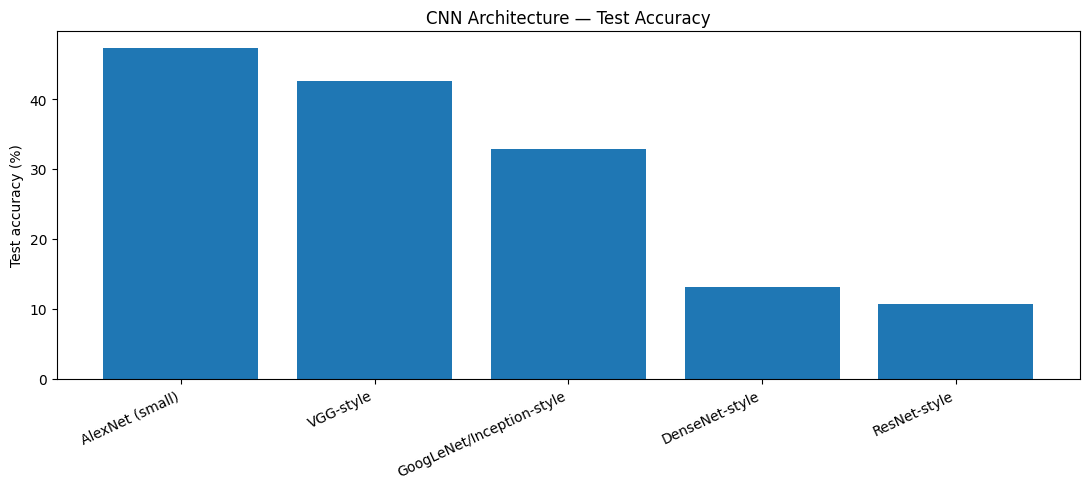

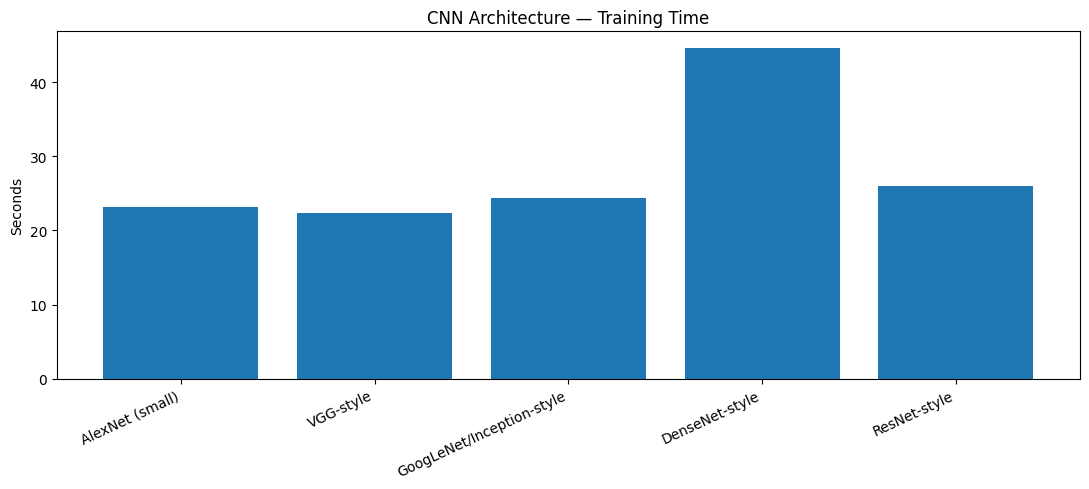

In [ ]:
results_df = pd.DataFrame(results).sort_values(
    "Test accuracy (%)", ascending=False
).reset_index(drop=True)
display(results_df)
best_architecture = results_df.iloc[0]["Architecture"]
print("Highest test accuracy in this run:", best_architecture)

plt.figure(figsize=(11, 5))
plt.bar(results_df["Architecture"], results_df["Test accuracy (%)"])
plt.ylabel("Test accuracy (%)")
plt.title("CNN Architecture — Test Accuracy")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

plt.figure(figsize=(11, 5))
plt.bar(results_df["Architecture"], results_df["Training time (sec)"])
plt.ylabel("Seconds")
plt.title("CNN Architecture — Training Time")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

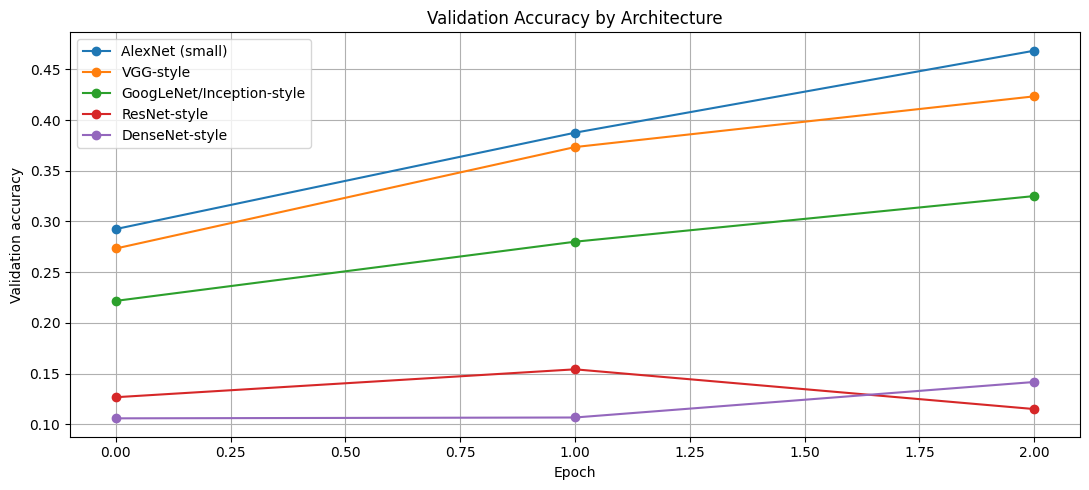

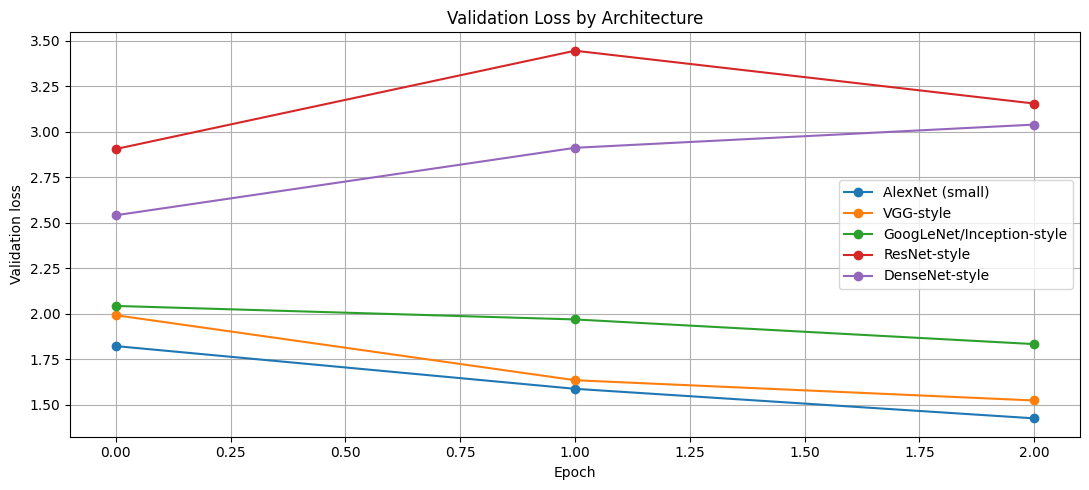

In [ ]:
# Validation curves
plt.figure(figsize=(11, 5))
for name, h in histories.items():
    plt.plot(h["val_accuracy"], marker="o", label=name)
plt.xlabel("Epoch")
plt.ylabel("Validation accuracy")
plt.title("Validation Accuracy by Architecture")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

plt.figure(figsize=(11, 5))
for name, h in histories.items():
    plt.plot(h["val_loss"], marker="o", label=name)
plt.xlabel("Epoch")
plt.ylabel("Validation loss")
plt.title("Validation Loss by Architecture")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## 11. Example predictions

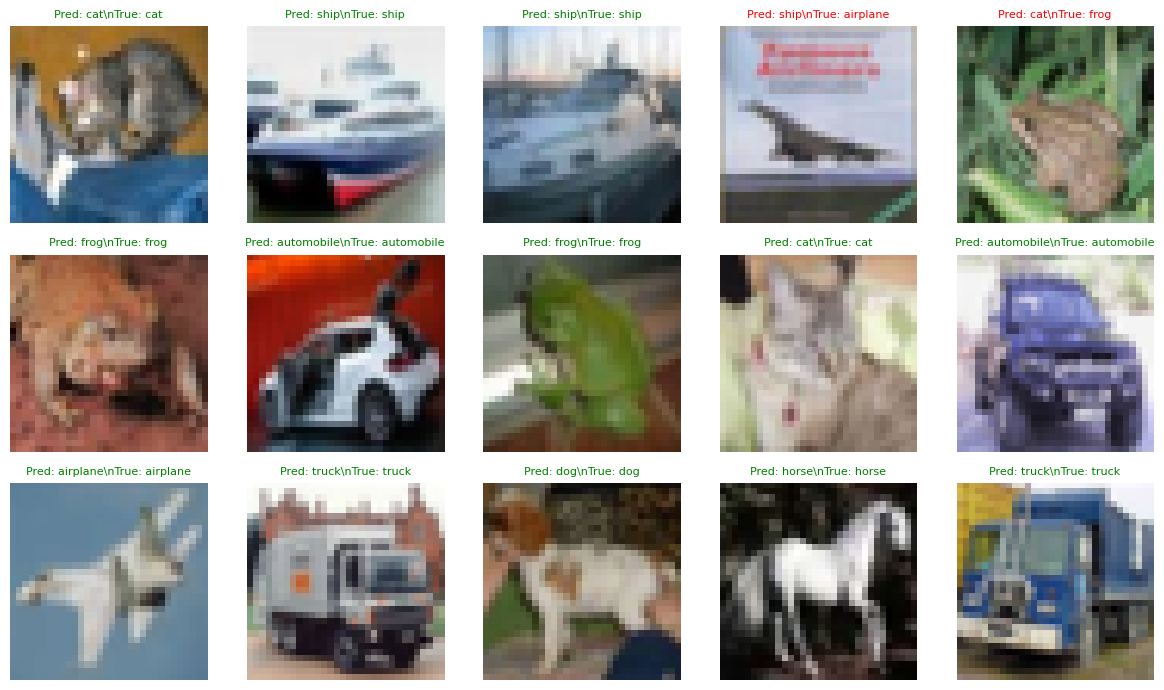

In [ ]:
best_model = models[best_architecture]
probs = best_model.predict(x_test[:15], verbose=0)
preds = np.argmax(probs, axis=1)

plt.figure(figsize=(12, 7))
for i in range(15):
    plt.subplot(3, 5, i+1)
    plt.imshow(x_test[i])
    correct = preds[i] == y_test[i]
    plt.title(f"Pred: {class_names[preds[i]]}\\nTrue: {class_names[y_test[i]]}",
              color="green" if correct else "red", fontsize=8)
    plt.axis("off")
plt.tight_layout()
plt.show()

## 12. Final comparison — revision notes

| Architecture | Main idea | Strength | Limitation |
|---|---|---|---|
| AlexNet | Conv layers, ReLU, dropout | Historic breakthrough; straightforward flow | Original fully connected layers are large |
| VGG | Repeated 3×3 convolutions | Simple, repeatable blocks | Can use many parameters and memory |
| GoogLeNet/Inception | Parallel filters + concatenate | Multi-scale feature extraction | More complex branching |
| ResNet | Shortcut addition: F(x) + x | Helps train deeper networks | Tensor shapes must match for addition |
| DenseNet | Concatenate earlier feature maps | Reuses features | Concatenation can increase memory use |

**Quick questions**
1. Repeated 3×3 convolution blocks? **VGG**
2. Parallel filter paths? **GoogLeNet/Inception**
3. Adds shortcut output? **ResNet**
4. Concatenates earlier features? **DenseNet**
5. ResNet vs DenseNet? **ResNet adds; DenseNet concatenates.**

**Interpretation:** higher test accuracy is better; lower test loss is generally better; training time indicates speed on this runtime. Short runs are preliminary. For stronger conclusions, use more epochs, more training data, and repeat experiments. These are compact educational versions, not exact AlexNet, VGG-16, GoogLeNet, ResNet-50, or DenseNet-121.